# **Mini-Proyecto 2 - Análisis de datos biológicos con DM y ML**

## Planteamiento del problema

El proyecto **TCGA (The Cancer Genome Atlas)** contiene perfiles multi-ómicos de decenas de miles de muestras tumorales. Trabajar con la colección completa (disponible en el Xena Browser, https://xenabrowser.net/heatmap/) excede los recursos de un entorno gratuito de Google Colab (RAM y disco limitados), por lo que se opta por un subconjunto manejable. *(Nota: el tamaño exacto de la colección completa depende de qué cohortes y capas ómicas se descarguen; si se quiere citar una cifra, verificarla en la fuente.)*

Para verificar la **factibilidad del análisis** en un entorno accesible, en este trabajo se utiliza una **versión reducida y pública del mismo proyecto TCGA-PANCAN**, distribuida por el repositorio UCI Machine Learning (ID 401) [https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq]. Esta versión conserva la estructura biológica del dataset (perfiles de expresión génica de cinco tipos tumorales) pero restringe el número de muestras a 801, lo que permite ejecutar el pipeline completo de data mining y machine learning en Colab sin perder validez metodológica. Si el pipeline funciona sobre esta versión, el mismo enfoque podría escalarse al dataset completo con recursos computacionales adecuados.

---

**Descripción del subconjunto utilizado.** El dataset contiene perfiles de expresión génica (niveles de ARN mensajero medidos por secuenciación) de **801 muestras de tumores humanos** provenientes del proyecto TCGA. Cada muestra describe la expresión de **20.531 genes**, y está etiquetada con el tejido de origen del tumor, distribuido en cinco clases: **BRCA** (mama), **KIRC** (riñón), **COAD** (colon), **LUAD** (pulmón) y **PRAD** (próstata).

**Objetivo del análisis.** Construir y evaluar modelos de aprendizaje supervisado capaces de clasificar el tipo de tumor a partir del perfil de expresión génica de una muestra. Se busca, además, identificar qué genes son los más informativos para esta tarea, comparar el desempeño de dos modelos (Random Forest y Árbol de Decisión) y evaluar si la estructura del dataset permite una buena separación de clases en un espacio de baja dimensión.

**Relevancia biológica.** Si un modelo puede predecir el tejido de origen de un tumor a partir de su transcriptoma, esto resulta útil como herramienta de diagnóstico asistido, especialmente en muestras de origen incierto (metástasis de primario desconocido). La identificación de los genes más importantes también puede aportar pistas sobre marcadores moleculares específicos de tejido.

In [1]:
# --- Carga del dataset ---
import pandas as pd
import numpy as np
import os

In [2]:
# Cargar data y labels (la versión de UCI trae el dataset en dos archivos)
X_raw = pd.read_csv('data.csv', index_col=0)
y_raw = pd.read_csv('labels.csv', index_col=0)

# Unir en un único DataFrame (features + etiqueta)
datos = X_raw.copy()
datos['tipo_tumor'] = y_raw['Class']

print("Shape del dataset:", datos.shape)
datos.iloc[:5, :5]   # mostrar solo las primeras columnas para no saturar la salida

Shape del dataset: (801, 20532)


,gene_0,gene_1,gene_2,gene_3,gene_4
sample_0,0.0,2.017209,3.265527,5.478487,10.431999
sample_1,0.0,0.592732,1.588421,7.586157,9.623011
sample_2,0.0,3.511759,4.327199,6.881787,9.870730
sample_3,0.0,3.663618,4.507649,6.659068,10.196184
sample_4,0.0,2.655741,2.821547,6.539454,9.738265


## 1- **Descripción del conjunto de datos**

In [3]:
print("Columnas totales:", datos.shape[1])
print("Filas (muestras):", datos.shape[0])
print("Variable objetivo: 'tipo_tumor'")
print("\nClases y frecuencias:")
print(datos['tipo_tumor'].value_counts())
print("\nCantidad de features numéricos:", datos.shape[1] - 1)
print("Cantidad de features categóricos (sin contar la etiqueta):", 0)

Columnas totales: 20532
Filas (muestras): 801
Variable objetivo: 'tipo_tumor'

Clases y frecuencias:
tipo_tumor
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Cantidad de features numéricos: 20531
Cantidad de features categóricos (sin contar la etiqueta): 0


Cada columna de las 20.531 features representa un gen, identificado en esta versión con la nomenclatura anónima `gene_NNNN` (los identificadores originales Ensembl fueron reemplazados por el repositorio UCI para evitar problemas de licenciamiento). El valor de cada celda corresponde al nivel de expresión normalizado de ese gen en una muestra tumoral particular.

**Descripción de las columnas** (20.532 en el DataFrame unido):

| Columna(s) | Tipo | Descripción |
|---|---|---|
| Índice (`sample_0` … `sample_800`) | identificador | Una fila por muestra tumoral. No es una feature. |
| `gene_0` … `gene_20530` (20.531 columnas) | numérica continua | Nivel de expresión génica (ARNm por secuenciación) del gen correspondiente en esa muestra. Los nombres reales de los genes fueron anonimizados por el repositorio UCI. |
| `tipo_tumor` | categórica (objetivo) | Tejido de origen del tumor: BRCA, COAD, KIRC, LUAD o PRAD. Se agrega al unir `labels.csv`. |
| `tipo_tumor_cod` | entera (objetivo codificado) | Versión numérica de `tipo_tumor` generada con `LabelEncoder` en la sección 2.2. |

El dataset presenta **801 muestras** y **20.531 features numéricos** correspondientes a genes, más una variable objetivo categórica (`tipo_tumor`) con **5 clases**. Todas las features son numéricas continuas (niveles de expresión normalizados); no hay variables categóricas en las features de entrada.

La distribución de clases es la siguiente:

| Clase | Muestras | Porcentaje |
|-------|----------|------------|
| BRCA  | 300      | 37.45%     |
| KIRC  | 146      | 18.23%     |
| LUAD  | 141      | 17.60%     |
| PRAD  | 136      | 16.98%     |
| COAD  | 78       | 9.74%      |

Se trata de un dataset **moderadamente desbalanceado**, con una relación de 3.85 entre la clase mayoritaria (BRCA) y la minoritaria (COAD). Esta asimetría se tendrá en cuenta al evaluar los modelos: el *accuracy* global puede ocultar un mal desempeño sobre la clase minoritaria, por lo que se reportarán también *precision*, *recall* y *F1* por clase.

Los valores de expresión génica varían entre **0.0** y **20.78**. Dado que las escalas entre genes son muy distintas y que la mayoría de los genes presentan valores bajos, la **normalización previa a PCA** resulta imprescindible.

In [4]:
# Mínimos y máximos de las features numéricas (sobre todo el dataset es mucho,
# así que calculamos y resumimos)
desc = datos.drop(columns='tipo_tumor').describe().T
print("Resumen global de las features numéricas:")
print(desc[['min', 'max', 'mean']].describe())
print("\nEjemplos de mín/máx por algunos genes:")
print(desc[['min', 'max']].head(10))

Resumen global de las features numéricas:
                min           max          mean
count  20531.000000  20531.000000  20531.000000
mean       3.458031     10.569705      6.443322
std        3.512085      3.468603      3.835064
min        0.000000      0.000000      0.000000
25%        0.000000      9.292348      2.939933
50%        2.614050     11.291758      7.515841
75%        6.726899     12.715971      9.572860
max       14.841294     20.778829     16.430442

Ejemplos de mín/máx por algunos genes:
             min        max
gene_0  0.000000   1.482332
gene_1  0.000000   6.237034
gene_2  0.000000   6.063484
gene_3  5.009284  10.129528
gene_4  8.435999  11.355621
gene_5  0.000000   0.000000
gene_6  3.930747  10.718190
gene_7  0.000000   2.779008
gene_8  0.000000   1.785592
gene_9  0.000000   4.067604


> **Nota:** con 20.531 genes no tiene sentido imprimir los 20.531 mín/máx. Vamos con mostrar un resumen global (min de los mínimos, max de los máximos, etc.) y algunos ejemplos. Lo importante es entender que las escalas son muy distintas entre genes. *Por eso más adelante hay que normalizar.*

In [5]:
# Mínimo y máximo globales, y genes con mayor rango de expresión
X_feat = datos.drop(columns='tipo_tumor')
print("Mínimo global de expresión:", X_feat.values.min())
print("Máximo global de expresión:", X_feat.values.max())

rangos = (desc['max'] - desc['min']).sort_values(ascending=False)
print("\nGenes con mayor rango (max - min):")
print(desc.loc[rangos.index[:5], ['min', 'max']])

print("\nGenes con expresión 0 en todas las muestras:", (desc['max'] == 0).sum())

Mínimo global de expresión: 0.0
Máximo global de expresión: 20.7788287118

Genes con mayor rango (max - min):
            min        max
gene_4160   0.0  20.778829
gene_4319   0.0  20.615526
gene_9176   0.0  20.585565
gene_15898  0.0  20.384155
gene_13298  0.0  20.378747

Genes con expresión 0 en todas las muestras: 267


In [6]:
# Como no hay features categóricos, no aplicamos unique() sobre ellos.
# Pero sí verificamos que la columna objetivo tenga 5 valores únicos:
print("Valores únicos de la variable objetivo:", datos['tipo_tumor'].unique())
print("Cantidad de clases:", datos['tipo_tumor'].nunique())

Valores únicos de la variable objetivo: ['PRAD' 'LUAD' 'BRCA' 'KIRC' 'COAD']
Cantidad de clases: 5


## **2- Preparación de los datos**

### **2.1 Valores faltantes**


In [7]:
# ¿Hay valores faltantes?
nulos_por_col = datos.isnull().sum()
print("Total de valores nulos en el dataset:", nulos_por_col.sum())
print("Columnas con al menos un nulo:", (nulos_por_col > 0).sum())

Total de valores nulos en el dataset: 0
Columnas con al menos un nulo: 0


**Valores faltantes.** El dataset **no presenta valores nulos** en ninguna columna (total de nulos = 0). En consecuencia, no fue necesario eliminar filas ni aplicar técnicas de imputación, y se conservaron las 801 muestras completas para el análisis.

### **2.2 Codificación de la etiqueta**

In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
datos['tipo_tumor_cod'] = le.fit_transform(datos['tipo_tumor'])

# Ver el mapeo clase -> número
mapeo = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapeo de clases:", mapeo)

Mapeo de clases: {'BRCA': np.int64(0), 'COAD': np.int64(1), 'KIRC': np.int64(2), 'LUAD': np.int64(3), 'PRAD': np.int64(4)}


### **2.3 Guardar el DataFrame limpio**

In [9]:
# Guardamos el DataFrame sin la columna original de texto para no duplicar
datos_limpios = datos.drop(columns='tipo_tumor')
datos_limpios.to_csv('datos_limpios.txt', index=False)
print("Archivo guardado. Shape:", datos_limpios.shape)

Archivo guardado. Shape: (801, 20532)


**Codificación de la variable objetivo.**

La etiqueta categórica se transformó a valores numéricos con `LabelEncoder`, generando el siguiente mapeo:

| Clase | Código |
|-------|--------|
| BRCA  | 0      |
| COAD  | 1      |
| KIRC  | 2      |
| LUAD  | 3      |
| PRAD  | 4      |

No se aplicó codificación a las features de entrada, ya que todas son numéricas. El DataFrame limpio (features + etiqueta codificada) se guardó en `datos_limpios.txt` para trazabilidad.

### **2.4 ¿Clases balanceadas?**

In [10]:
conteo = datos['tipo_tumor_cod'].value_counts().sort_index()
print("Conteo por clase codificada:")
print(conteo)
print("\nProporción:")
print((conteo / conteo.sum()).round(3))

Conteo por clase codificada:
tipo_tumor_cod
0    300
1     78
2    146
3    141
4    136
Name: count, dtype: int64

Proporción:
tipo_tumor_cod
0    0.375
1    0.097
2    0.182
3    0.176
4    0.170
Name: count, dtype: float64


Como se anticipó en la sección anterior, el dataset está moderadamente desbalanceado (ratio 3.85:1 entre BRCA y COAD). Este punto no impide el entrenamiento pero refuerza la necesidad de reportar métricas por clase, no solo el *accuracy* global.

## **3- Visualización y Análisis de componentes principales (PCA)**

### **3.1 Dimensiones y unidades**

Con 20.531 genes, cualquier representación gráfica directa es imposible: se trata de un problema de muy alta dimensionalidad. Todas las features comparten unidades (niveles de expresión), pero sus **escalas varían significativamente**, lo que hace que la normalización con `MinMaxScaler` sea un paso previo recomendable. Sin ella, PCA (que busca las direcciones de máxima varianza) quedaría dominado por los genes con mayor varianza absoluta, sin que eso implique que sean los más informativos (ver explicación en 3.3).

### **3.2 Separar X e y**


In [11]:
# X: features; y: etiquetas codificadas
X = datos.drop(columns=['tipo_tumor', 'tipo_tumor_cod']).values
y = datos['tipo_tumor_cod'].values

print("X:", X.shape)
print("y:", y.shape, "| clases:", np.unique(y))

X: (801, 20531)
y: (801,) | clases: [0 1 2 3 4]


### **3.3 Normalizar con MinMaxScaler**

**¿Por qué es importante normalizar antes de PCA?** PCA busca las direcciones de máxima varianza. Si las variables están en escalas distintas, las de mayor varianza absoluta dominan los primeros componentes aunque no aporten más información biológica. `MinMaxScaler` lleva cada gen al rango [0, 1], de modo que todos compiten en igualdad de condiciones. *Matiz:* al estirar cada gen a [0, 1], los genes con rango muy pequeño (casi ruido) también se amplifican; estandarizar (`StandardScaler`) o filtrar genes de baja expresión son alternativas válidas.

In [12]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Rango original de una feature cualquiera:", X[:, 0].min(), "-", X[:, 0].max())
print("Rango post-escalado:", X_scaled[:, 0].min(), "-", X_scaled[:, 0].max())

Rango original de una feature cualquiera: 0.0 - 1.48233202075
Rango post-escalado: 0.0 - 1.0


### **3.4 Aplicar PCA y ver varianza explicada**

In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por PC1:", round(pca.explained_variance_ratio_[0]*100, 2), "%")
print("Varianza explicada por PC2:", round(pca.explained_variance_ratio_[1]*100, 2), "%")
print("Varianza explicada PC1+PC2:", round(pca.explained_variance_ratio_.sum()*100, 2), "%")

Varianza explicada por PC1: 12.69 %
Varianza explicada por PC2: 9.4 %
Varianza explicada PC1+PC2: 22.1 %


**Varianza explicada.**

Tras normalizar y aplicar PCA con dos componentes, se obtuvo:

| Componente | Varianza explicada |
|------------|--------------------|
| PC1        | 12.69%             |
| PC2        | 9.40%              |
| **PC1+PC2**| **22.10%**         |

En un dataset de 20.531 dimensiones, dos componentes retienen **22,10 %** de la varianza: la proyección 2D no captura toda la estructura de los datos, pero conserva una fracción apreciable de la variabilidad global, suficiente para una visualización exploratoria. Que haya una separación visible entre clases en solo 2 componentes es lo más relevante (ver gráfico 3.5), no el porcentaje en sí.

### **3.5 Gráfico 2D coloreado por clase**

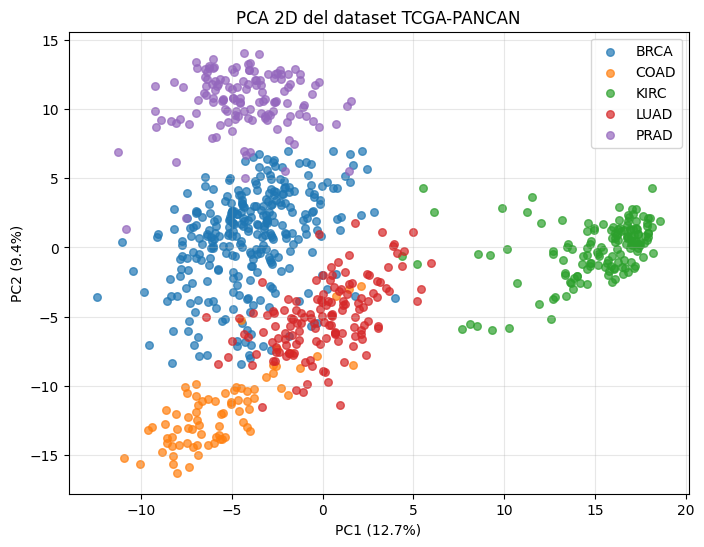

In [14]:
plt.figure(figsize=(8, 6))
for clase in np.unique(y):
    mask = y == clase
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=le.inverse_transform([clase])[0], alpha=0.7, s=30)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA 2D del dataset TCGA-PANCAN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Observación sobre la separación visual.**

En el gráfico 2D coloreado por clase se observan agrupamientos claros, lo que anticipa una buena clasificabilidad del dataset. Sin embargo, la superposición parcial entre algunas clases (especialmente entre tejidos con perfiles transcriptómicos parecidos) sugiere que la separación completa requiere más dimensiones que las dos retenidas aquí.

### **3.6 Vectores de carga y biplot**

In [15]:
# Vectores de carga (loading vectors): cuánto pesa cada feature en cada PC
cargas = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=datos.drop(columns=['tipo_tumor', 'tipo_tumor_cod']).columns
)
cargas['magnitud_PC1'] = cargas['PC1'].abs()
cargas['magnitud_PC2'] = cargas['PC2'].abs()

print("Top 10 features más relevantes para PC1:")
print(cargas.sort_values('magnitud_PC1', ascending=False).head(10)[['PC1']])

print("\nTop 10 features más relevantes para PC2:")
print(cargas.sort_values('magnitud_PC2', ascending=False).head(10)[['PC2']])

Top 10 features más relevantes para PC1:
                 PC1
gene_1858   0.037822
gene_219    0.036245
gene_13818  0.036113
gene_1510   0.035227
gene_220    0.035191
gene_16169  0.034995
gene_16246  0.034694
gene_12078  0.034397
gene_450    0.034279
gene_7116   0.034221

Top 10 features más relevantes para PC2:
                 PC2
gene_9175   0.035381
gene_9176   0.033119
gene_3737   0.032069
gene_4456   0.031206
gene_12848  0.030820
gene_9177   0.030756
gene_14623  0.030043
gene_12995  0.030003
gene_9075   0.029924
gene_10141  0.029785


**Genes más relevantes según las cargas (loadings).**

- **PC1:** `gene_1858` (0.0378), `gene_219` (0.0362), `gene_13818` (0.0361), `gene_1510` (0.0352), `gene_220` (0.0352).
- **PC2:** `gene_9175` (0.0354), `gene_9176` (0.0331), `gene_3737` (0.0321), `gene_4456` (0.0312), `gene_12848` (0.0308).

Estos genes son los que más contribuyen a la varianza proyectada en cada eje.

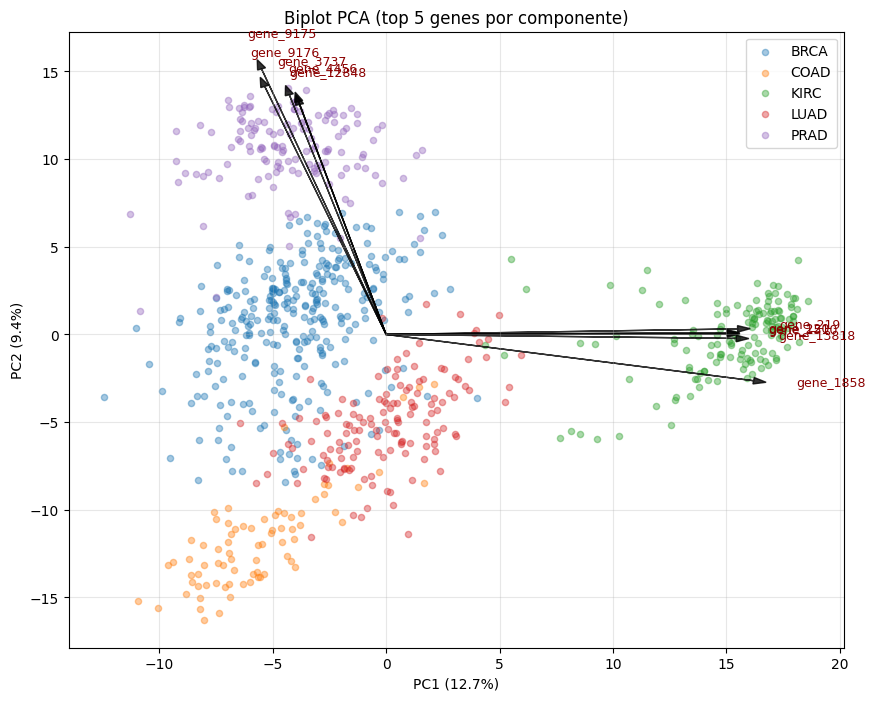

Flecha más larga sobre el eje PC1: gene_1858 (carga = 0.0378)
Flecha más larga sobre el eje PC2: gene_9175 (carga = 0.0354)


In [16]:
# Biplot: puntos de las muestras + flechas de los genes con mayor carga en PC1 y PC2
top_n = 5
top_pc1 = cargas.sort_values('magnitud_PC1', ascending=False).head(top_n)
top_pc2 = cargas.sort_values('magnitud_PC2', ascending=False).head(top_n)
top_features = pd.concat([top_pc1, top_pc2]).drop_duplicates()

plt.figure(figsize=(10, 8))
for clase in np.unique(y):
    mask = y == clase
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=le.inverse_transform([clase])[0], alpha=0.4, s=20)

# Escalar las flechas para que ocupen ~90% del rango de los puntos
escala = 0.9 * np.abs(X_pca).max() / np.abs(top_features[['PC1', 'PC2']].values).max()
for nombre, fila in top_features.iterrows():
    plt.arrow(0, 0, fila['PC1'] * escala, fila['PC2'] * escala,
              color='black', alpha=0.8, length_includes_head=True,
              head_width=0.02 * np.abs(X_pca).max())
    plt.text(fila['PC1'] * escala * 1.08, fila['PC2'] * escala * 1.08,
             nombre, fontsize=9, color='darkred')

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Biplot PCA (top 5 genes por componente)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Respuesta explícita: gen cuya flecha proyecta más sobre cada eje
g1 = top_features['PC1'].abs().idxmax()
g2 = top_features['PC2'].abs().idxmax()
print(f"Flecha más larga sobre el eje PC1: {g1} (carga = {top_features.loc[g1, 'PC1']:.4f})")
print(f"Flecha más larga sobre el eje PC2: {g2} (carga = {top_features.loc[g2, 'PC2']:.4f})")

**Interpretación del biplot.** Las flechas del biplot son los vectores de carga, por lo que la relevancia de cada gen se lee como la proyección de su flecha sobre cada eje:

- **PC1:** el gen más relevante es **`gene_1858`** (carga 0,0378), el de la flecha que más se extiende sobre el eje horizontal.
- **PC2:** el gen más relevante es **`gene_9175`** (carga 0,0354), el de la flecha que más se extiende sobre el eje vertical.

Esto coincide con la tabla de cargas de 3.6 (la celda anterior imprime el mismo resultado). Un matiz importante: dentro de cada componente, las cargas de los primeros genes son **muy parecidas** (PC1: 0,0378; 0,0362; 0,0361; …), es decir, PC1 y PC2 son combinaciones de **muchos genes con pesos similares** y no dependen de un único gen. Por eso conviene hablar de "los genes más cargados" y no de "el gen determinante". Las flechas en direcciones similares indican genes cuya expresión varía de forma conjunta entre las muestras.

## **4- Modelo 1: Random Forest con validación OOB**

### **4.1 Verificar X e y**

In [17]:
print("Tipo de X:", type(X), "| Shape:", X.shape)
print("Tipo de y:", type(y), "| Shape:", y.shape)
print("Primeras 5 etiquetas codificadas:", y[:5])

Tipo de X: <class 'numpy.ndarray'> | Shape: (801, 20531)
Tipo de y: <class 'numpy.ndarray'> | Shape: (801,)
Primeras 5 etiquetas codificadas: [4 3 4 4 0]


### **4.2 Entrenar Random Forest con OOB**

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
    max_features='sqrt'
)
rf.fit(X_scaled, y)  # usamos X normalizado, coherente con lo que hicimos en PCA

print(f"Precisión OOB: {rf.oob_score_:.4f}")
print("Clases ordenadas:", rf.classes_)
print("Nombres de clases:", [le.inverse_transform([c])[0] for c in rf.classes_])

Precisión OOB: 0.9963
Clases ordenadas: [0 1 2 3 4]
Nombres de clases: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']


Se entrenó un Random Forest con 500 árboles, `max_features='sqrt'` y evaluación Out-of-Bag. El **OOB score obtenido fue 0.9963** (99.63%), lo que indica que el modelo generaliza de forma casi perfecta sobre muestras no utilizadas durante el entrenamiento de cada árbol.

**¿Qué es OOB?**

Cada árbol del bosque se entrena con una muestra bootstrap (con reemplazo).

Aproximadamente 1/3 de las muestras queda afuera de cada árbol: esas son las "out-of-bag". OOB score = accuracy promedio evaluando cada muestra con los árboles que no la vieron. Es una validación cruzada gratuita, sin separar test aparte.

### 4.3 Matriz de confusión con predicciones OOB


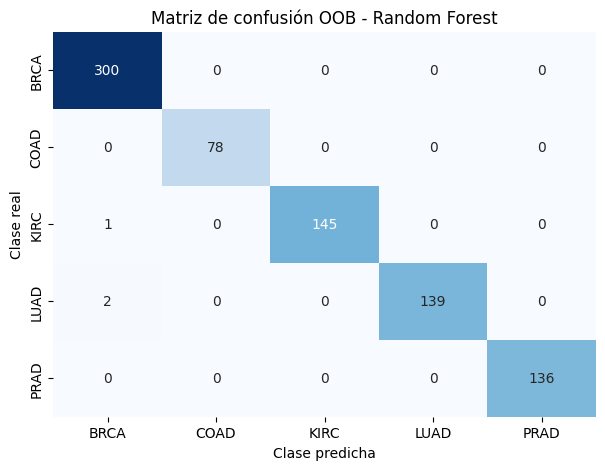

              precision    recall  f1-score   support

        BRCA       0.99      1.00      1.00       300
        COAD       1.00      1.00      1.00        78
        KIRC       1.00      0.99      1.00       146
        LUAD       1.00      0.99      0.99       141
        PRAD       1.00      1.00      1.00       136

    accuracy                           1.00       801
   macro avg       1.00      1.00      1.00       801
weighted avg       1.00      1.00      1.00       801



In [19]:
# Predicciones OOB (probabilidades)
oob_proba = rf.oob_decision_function_
oob_pred = rf.classes_[np.argmax(oob_proba, axis=1)]

cm = confusion_matrix(y, oob_pred, labels=rf.classes_)
nombres = [le.inverse_transform([c])[0] for c in rf.classes_]
cm_df = pd.DataFrame(cm, index=nombres, columns=nombres)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matriz de confusión OOB - Random Forest")
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.show()

print(classification_report(y, oob_pred, target_names=nombres))

**Matriz de confusión OOB.**

| Real \ Predicho | BRCA | COAD | KIRC | LUAD | PRAD |
|------------------|------|------|------|------|------|
| **BRCA**         | 300  | 0    | 0    | 0    | 0    |
| **COAD**         | 0    | 78   | 0    | 0    | 0    |
| **KIRC**         | 1    | 0    | 145  | 0    | 0    |
| **LUAD**         | 2    | 0    | 0    | 139  | 0    |
| **PRAD**         | 0    | 0    | 0    | 0    | 136  |

Se registran **solo 3 errores sobre 801 muestras** (0.37%). Todos los errores implican una **clasificación errónea hacia BRCA** de muestras pertenecientes a KIRC (1 caso) y LUAD (2 casos). Este patrón es consistente con la clase BRCA siendo la mayoritaria y potencialmente solapando en frontera con otros adenocarcinomas.


**Métricas por clase.**

| Clase | Precision | Recall | F1   | Soporte |
|-------|-----------|--------|------|---------|
| BRCA  | 0.9901    | 1.0000 | 0.9950 | 300   |
| COAD  | 1.0000    | 1.0000 | 1.0000 | 78    |
| KIRC  | 1.0000    | 0.9932 | 0.9966 | 146   |
| LUAD  | 1.0000    | 0.9858 | 0.9929 | 141   |
| PRAD  | 1.0000    | 1.0000 | 1.0000 | 136   |

La **clase minoritaria (COAD) se clasifica perfectamente**, lo cual es destacable porque indica que el desbalance no impacta en el desempeño. Las clases con algún error (KIRC y LUAD) presentan F1 ligeramente por debajo de 1 pero igualmente superior a 0.99.

### **4.4 Importancia de features (top N)**

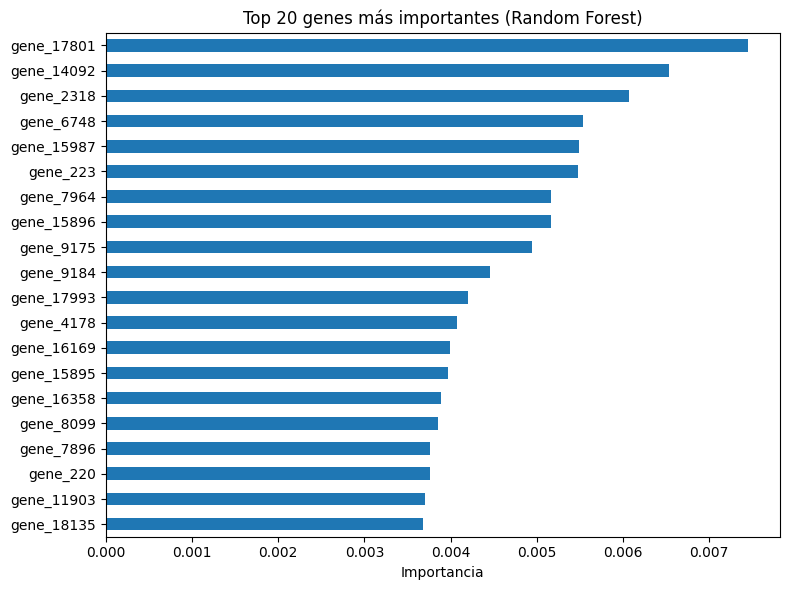

In [20]:
importancias = pd.Series(rf.feature_importances_,
                         index=datos.drop(columns=['tipo_tumor', 'tipo_tumor_cod']).columns)
top20 = importancias.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
top20.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel("Importancia")
plt.title("Top 20 genes más importantes (Random Forest)")
plt.tight_layout()
plt.show()

In [21]:
print(top20)

gene_17801    0.007450
gene_14092    0.006537
gene_2318     0.006066
gene_6748     0.005539
gene_15987    0.005492
gene_223      0.005478
gene_7964     0.005170
gene_15896    0.005163
gene_9175     0.004939
gene_9184     0.004461
gene_17993    0.004206
gene_4178     0.004077
gene_16169    0.003999
gene_15895    0.003974
gene_16358    0.003891
gene_8099     0.003850
gene_7896     0.003766
gene_220      0.003765
gene_11903    0.003705
gene_18135    0.003684
dtype: float64


**Features más importantes (top 10).**

Los genes con mayor importancia promedio son `gene_17801` (0.0074), `gene_14092` (0.0065), `gene_2318` (0.0061), `gene_6748` (0.0055), `gene_15987` (0.0055), `gene_223` (0.0055), `gene_7964` (0.0052), `gene_15896` (0.0052), `gene_9175` (0.0049) y `gene_9184` (0.0045).

Las importancias son bajas en términos absolutos, lo cual es esperable en un ensemble de 500 árboles entrenados sobre 20.531 features: la contribución al desempeño está **distribuida entre miles de genes**, lo que aporta robustez frente al ruido.


### **4.5 Ventajas de OOB vs test independiente**

**Ventajas de la evaluación OOB:**

- **No hay que reservar datos para test:** todas las muestras se usan para entrenar el bosque. Es útil con 801 muestras, donde apartar un 20–25 % pesa.
- **Es "gratuita":** sale del mismo entrenamiento, sin repetir ajustes como en una validación cruzada.
- **Cada muestra se predice solo con los árboles que no la vieron** (aprox. 1/3 de los árboles), de modo que la estimación no es optimista como lo sería la accuracy sobre los datos de entrenamiento.
- Se obtienen predicciones por muestra (`oob_decision_function_`), que permiten armar la matriz de confusión con todo el dataset.

**Diferencia con un test independiente:** el test independiente es un conjunto que el modelo nunca vio y que además **no participa en ninguna decisión del modelado**; el OOB es una estimación interna: cada predicción usa un subconjunto del bosque (no el bosque completo) y las muestras OOB sí pertenecen al conjunto con el que se eligieron hiperparámetros y preprocesamiento. Por eso el OOB suele ser una buena aproximación, pero no reemplaza a un test externo cuando se quiere reportar rendimiento final. Además, **no es directamente comparable** con la accuracy de un modelo evaluado sobre otro conjunto (ver sección 7).

## **5 - Modelo 2: Árbol de Decisión**

### **5.1 Train/test split y entrenamiento**

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

arbol = DecisionTreeClassifier(
    criterion='entropy',
    min_samples_leaf=5,
    min_impurity_decrease=0.01,
    random_state=42
)
arbol.fit(X_train, y_train)

y_pred_arbol = arbol.predict(X_test)

print(f"Accuracy en test: {accuracy_score(y_test, y_pred_arbol):.4f}")
print(f"Profundidad del árbol: {arbol.get_depth()}")
print(f"Número de hojas: {arbol.get_n_leaves()}")

Accuracy en test: 0.9801
Profundidad del árbol: 3
Número de hojas: 6


Se entrenó un Árbol de Decisión con `criterion='entropy'`, `min_samples_leaf=5` y `min_impurity_decrease=0.01`, sobre una partición 75/25 (600 muestras para entrenamiento, 201 para test) con estratificación por clase.

---
Nota sobre hiperparámetros: con 20.531 features el árbol puede volverse gigante.

Con:
* `min_samples_leaf=5`
* `min_impurity_decrease=0.01`

Controlamos el crecimiento y evitamos overfitting.

---

**Resultados en el conjunto de test.**

- **Accuracy: 0.9801** (98.01%).
- **Profundidad del árbol: 3.**
- **Número de hojas: 6.**

Es notable que un árbol de **solo 3 niveles** logre una precisión superior al 98%. Esto es coherente con lo observado en el PCA: el dataset presenta una estructura muy separable, y un puñado de genes permite discriminar la mayoría de las muestras. *(Con un único split de 201 muestras, cada error equivale a 0,5 puntos porcentuales; ver validación cruzada en la sección 7.)*

In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predicciones sobre el conjunto de test
y_pred_arbol = arbol.predict(X_test)

# Nombres de clases en el orden interno del árbol
nombres_arbol = [le.inverse_transform([c])[0] for c in arbol.classes_]

In [24]:
# Matriz de confusión
cm_arbol = confusion_matrix(y_test, y_pred_arbol, labels=arbol.classes_)
cm_arbol_df = pd.DataFrame(cm_arbol, index=nombres_arbol, columns=nombres_arbol)

print("Matriz de confusión — Árbol de Decisión (test):")
print(cm_arbol_df)

Matriz de confusión — Árbol de Decisión (test):
      BRCA  COAD  KIRC  LUAD  PRAD
BRCA    75     0     0     0     0
COAD     0    19     0     1     0
KIRC     0     0    37     0     0
LUAD     0     0     2    32     1
PRAD     0     0     0     0    34


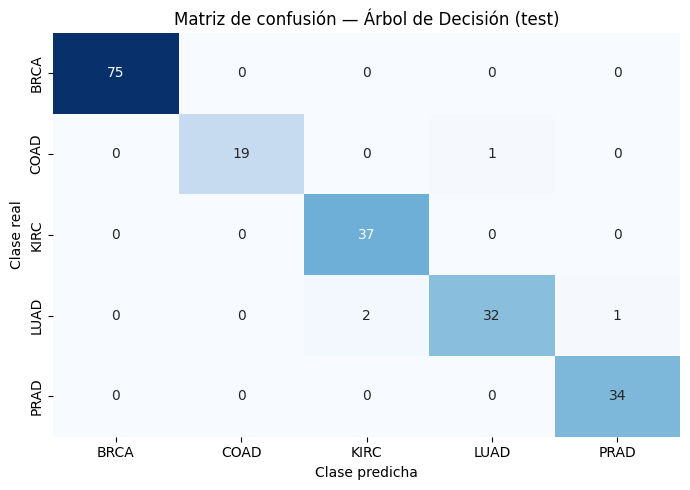

In [25]:
# Heatmap de la matriz
plt.figure(figsize=(7, 5))
sns.heatmap(cm_arbol_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matriz de confusión — Árbol de Decisión (test)")
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.tight_layout()
plt.show()

**Matriz de confusión (test).**

| Real \ Predicho | BRCA | COAD | KIRC | LUAD | PRAD |
|------------------|------|------|------|------|------|
| **BRCA**         | 75   | 0    | 0    | 0    | 0    |
| **COAD**         | 0    | 19   | 0    | 1    | 0    |
| **KIRC**         | 0    | 0    | 37   | 0    | 0    |
| **LUAD**         | 0    | 0    | 2    | 32   | 1    |
| **PRAD**         | 0    | 0    | 0    | 0    | 34   |

Se registran **4 errores sobre 201 muestras**: 1 COAD clasificado como LUAD, 2 LUAD clasificados como KIRC y 1 LUAD clasificado como PRAD. Todos los errores involucran a la clase LUAD (pulmón), lo que sugiere que las muestras de LUAD son las más heterogéneas o las más próximas a otros tejidos desde el punto de vista del transcriptoma.


In [26]:
# Reporte de clasificación (precision / recall / f1 por clase)
print("\nReporte de clasificación — Árbol de Decisión (test):")
print(classification_report(y_test, y_pred_arbol, target_names=nombres_arbol))


Reporte de clasificación — Árbol de Decisión (test):
              precision    recall  f1-score   support

        BRCA       1.00      1.00      1.00        75
        COAD       1.00      0.95      0.97        20
        KIRC       0.95      1.00      0.97        37
        LUAD       0.97      0.91      0.94        35
        PRAD       0.97      1.00      0.99        34

    accuracy                           0.98       201
   macro avg       0.98      0.97      0.97       201
weighted avg       0.98      0.98      0.98       201



**Métricas por clase.**

| Clase | Precision | Recall | F1   | Soporte test |
|-------|-----------|--------|------|--------------|
| BRCA  | 1.0000    | 1.0000 | 1.0000 | 75         |
| COAD  | 1.0000    | 0.9500 | 0.9744 | 20         |
| KIRC  | 0.9487    | 1.0000 | 0.9737 | 37         |
| LUAD  | 0.9697    | 0.9143 | 0.9412 | 35         |
| PRAD  | 0.9714    | 1.0000 | 0.9855 | 34         |

### **5.2 Comparar importancia con Random Forest**

In [27]:
imp_arbol = pd.Series(arbol.feature_importances_,
                      index=datos.drop(columns=['tipo_tumor', 'tipo_tumor_cod']).columns)
top_arbol = imp_arbol.sort_values(ascending=False).head(20)
print("Top 20 features según Árbol de Decisión:")
display(top_arbol)

Top 20 features según Árbol de Decisión:


,0
gene_7896,0.410425
gene_18135,0.231639
gene_439,0.200036
gene_3523,0.114361
gene_7623,0.043539
gene_13691,0.000000
gene_13690,0.000000
gene_13689,0.000000
gene_13688,0.000000
gene_13687,0.000000


In [28]:
# ¿Coinciden con el top 20 del Random Forest?
coinciden = set(top20.index) & set(top_arbol.index)
print(f"\nFeatures en común entre top-20 RF y top-20 Árbol: {len(coinciden)}")
print(coinciden)


Features en común entre top-20 RF y top-20 Árbol: 2
{'gene_18135', 'gene_7896'}


In [29]:
# ¿Cuántos genes usa realmente el árbol y cuánta importancia acumulan?
imp_pos = imp_arbol[imp_arbol > 0].sort_values(ascending=False)
print("Genes con importancia > 0 en el árbol:", len(imp_pos))
print("Importancia acumulada por gen:")
print(imp_pos.cumsum().round(4))

Genes con importancia > 0 en el árbol: 5
Importancia acumulada por gen:
gene_7896     0.4104
gene_18135    0.6421
gene_439      0.8421
gene_3523     0.9565
gene_7623     1.0000
dtype: float64


Las importancias están fuertemente concentradas en **cinco genes** (los únicos con importancia mayor que 0; coincide con los 5 cortes de un árbol de 6 hojas):

| Gen            | Importancia | Acumulada |
|----------------|-------------|-----------|
| `gene_7896`    | 0.4104      | 0.4104    |
| `gene_18135`   | 0.2316      | 0.6420    |
| `gene_439`     | 0.2000      | 0.8420    |
| `gene_3523`    | 0.1144      | 0.9564    |
| `gene_7623`    | 0.0435      | ≈ 1.0000  |

Los **primeros cuatro genes acumulan 95,64 %** de la importancia y el quinto aporta el resto (4,35 %); los demás 20.526 genes no se usan en ningún corte. Esta concentración es característica del modelo: el árbol selecciona **los genes con mayor ganancia de información en cada corte** y descarta el resto.

**Comparación de importancias con Random Forest.** Solo **2 genes coinciden entre los top-20** de ambos modelos: `gene_18135` y `gene_7896`. Esto no debe interpretarse como una contradicción entre modelos, sino como una diferencia de enfoque:

- El **árbol** es un modelo *parsimonioso*: selecciona pocas features y las explota al máximo, pero puede ser sensible a particularidades del conjunto de entrenamiento (y, cuando hay genes muy correlacionados, elige uno y descarta sus equivalentes).
- El **Random Forest** distribuye la importancia entre miles de genes, lo que aporta robustez y reduce la varianza, pero dificulta identificar unos pocos genes "estrella".

Que `gene_7896` y `gene_18135` aparezcan en ambos modelos (primero y segundo del árbol) sugiere que tienen capacidad discriminativa en este dataset, aunque la evidencia es modesta: un solo split, un solo conjunto de datos y solo 2 coincidencias.

### 5.3 Plot del árbol y guardado en PDF


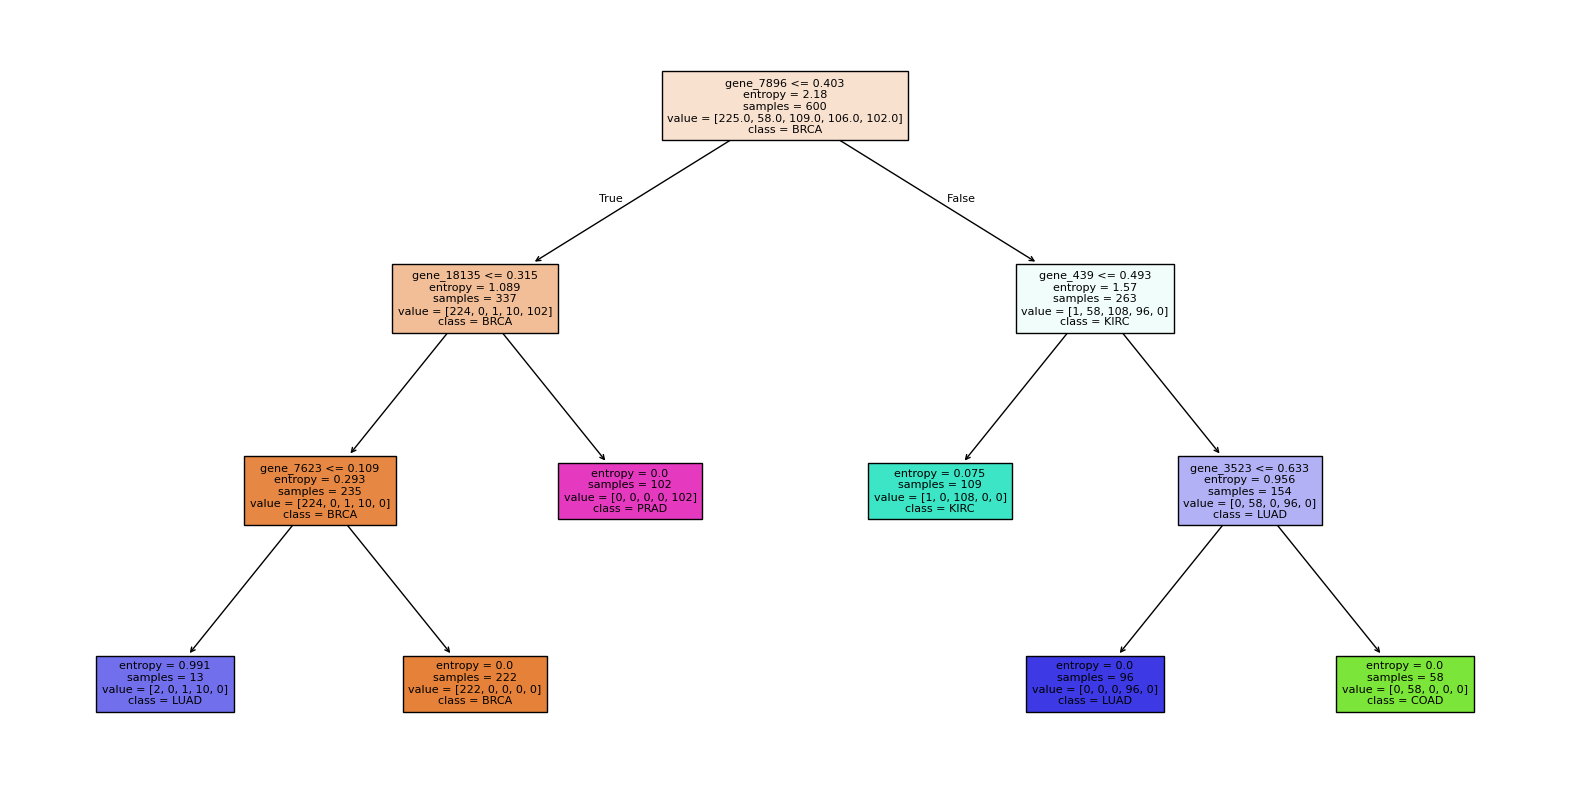

In [30]:
plt.figure(figsize=(20, 10))
plot_tree(arbol,
          filled=True,
          feature_names=datos.drop(columns=['tipo_tumor', 'tipo_tumor_cod']).columns,
          class_names=nombres,
          fontsize=8)
plt.savefig('decision_tree.pdf', format='pdf', bbox_inches='tight')
plt.show()

El árbol entrenado tiene profundidad 3 y 6 hojas, por lo que se grafica **completo** (no hace falta limitar la profundidad visual). Los nombres de los nodos son los de los genes usados en cada corte. El gráfico se guarda en `decision_tree.pdf`.

## **6 — Modelo 3: SVM lineal (simple)**

Se entrena una Máquina de Vectores de Soporte con kernel **lineal**, que es la opción natural cuando hay muchas más features (20.531) que muestras (801). A diferencia de los árboles, el SVM **sí es sensible a la escala**, por eso se arma un `Pipeline` con `MinMaxScaler`: el escalador se ajusta **solo con los datos de entrenamiento**, evitando fuga de información hacia el test. Se usa el **mismo split 75/25 estratificado** (`random_state=42`) que en el árbol, para que la comparación sea justa.

In [31]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Mismo split que el árbol (mismo random_state y stratify), pero sobre X SIN escalar
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
assert (y_te == y_test).all(), "El split no coincide con el del árbol"

svm = make_pipeline(MinMaxScaler(), SVC(kernel='linear', C=1.0, random_state=42))
svm.fit(X_tr, y_tr)

y_pred_svm = svm.predict(X_te)
acc_svm = accuracy_score(y_te, y_pred_svm)
print(f"Accuracy SVM en test: {acc_svm:.4f}")
print(f"Errores: {(y_pred_svm != y_te).sum()} de {len(y_te)}")
print(f"Vectores de soporte por clase: {svm[-1].n_support_}")

Accuracy SVM en test: 1.0000
Errores: 0 de 201
Vectores de soporte por clase: [81 19 18 50 15]


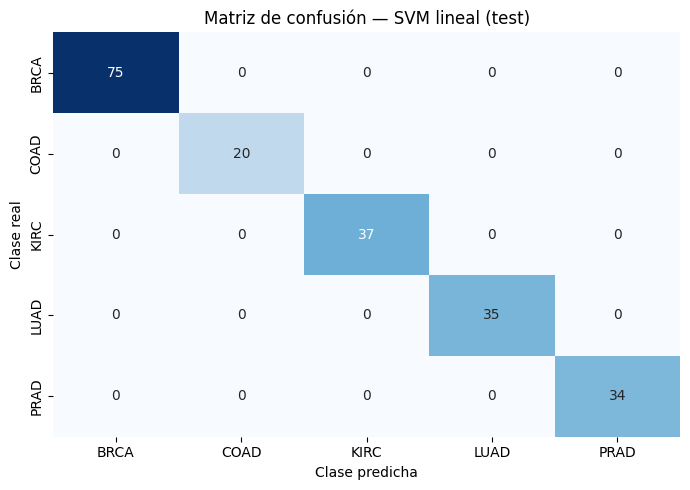

              precision    recall  f1-score   support

        BRCA       1.00      1.00      1.00        75
        COAD       1.00      1.00      1.00        20
        KIRC       1.00      1.00      1.00        37
        LUAD       1.00      1.00      1.00        35
        PRAD       1.00      1.00      1.00        34

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201



In [32]:
# Matriz de confusión y reporte del SVM
nombres_svm = [le.inverse_transform([c])[0] for c in svm[-1].classes_]
cm_svm = confusion_matrix(y_te, y_pred_svm, labels=svm[-1].classes_)
cm_svm_df = pd.DataFrame(cm_svm, index=nombres_svm, columns=nombres_svm)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_svm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matriz de confusión — SVM lineal (test)")
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.tight_layout()
plt.show()

print(classification_report(y_te, y_pred_svm, target_names=nombres_svm))

## **7 — Comparación justa de modelos**

Hasta aquí cada modelo se evaluó de forma distinta: el Random Forest con **OOB sobre las 801 muestras** y el árbol con **test de 201 muestras**. Esas cifras no son directamente comparables, y con 201 muestras un solo error cambia la accuracy en 0,5 puntos. Para comparar con más rigor se hacen dos cosas:

1. Evaluar el **Random Forest en el mismo split de test** que el árbol y el SVM.
2. Una **validación cruzada estratificada de 5 folds** para los tres modelos, con el `MinMaxScaler` dentro del `Pipeline` (se ajusta en cada fold solo con los datos de entrenamiento). Para los árboles el escalado no cambia los resultados, pero se mantiene el mismo procedimiento para los tres.

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1) Random Forest evaluado en el mismo split que el árbol y el SVM
rf_split = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1, max_features='sqrt')
rf_split.fit(X_train, y_train)
acc_rf_test = accuracy_score(y_test, rf_split.predict(X_test))
acc_arbol_test = accuracy_score(y_test, y_pred_arbol)
print(f"Accuracy en el MISMO test (n={len(y_test)}):")
print(f"  Random Forest: {acc_rf_test:.4f}")
print(f"  Árbol:         {acc_arbol_test:.4f}")
print(f"  SVM lineal:    {acc_svm:.4f}")

Accuracy en el MISMO test (n=201):
  Random Forest: 0.9900
  Árbol:         0.9801
  SVM lineal:    1.0000


In [34]:
# 2) Validación cruzada estratificada de 5 folds (escalado dentro del pipeline)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_cv = {
    'Random Forest': make_pipeline(MinMaxScaler(),
        RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, max_features='sqrt')),
    'Árbol de decisión': make_pipeline(MinMaxScaler(),
        DecisionTreeClassifier(criterion='entropy', min_samples_leaf=5,
                               min_impurity_decrease=0.01, random_state=42)),
    'SVM lineal': make_pipeline(MinMaxScaler(), SVC(kernel='linear', C=1.0, random_state=42)),
}

resultados_cv = {}
for nombre, modelo in modelos_cv.items():
    scores = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
    resultados_cv[nombre] = scores
    print(f"{nombre:18s} folds: {np.round(scores, 4)} | media = {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest      folds: [1.     1.     0.9938 1.     0.9875] | media = 0.9963 ± 0.0050
Árbol de decisión  folds: [0.9503 0.9625 0.9875 0.9688 0.9812] | media = 0.9701 ± 0.0133
SVM lineal         folds: [1.     1.     1.     1.     0.9938] | media = 0.9988 ± 0.0025


In [35]:
# Tabla comparativa final
n_feat_rf = int((rf.feature_importances_ > 0).sum())
n_feat_arbol = int((arbol.feature_importances_ > 0).sum())
n_feat_svm = int((np.abs(svm[-1].coef_).sum(axis=0) > 0).sum())

tabla = pd.DataFrame({
    'Acc. OOB (801 muestras)': [rf.oob_score_, np.nan, np.nan],
    f'Acc. test común (n={len(y_test)})': [acc_rf_test, acc_arbol_test, acc_svm],
    'Acc. CV 5-fold (media)': [resultados_cv[m].mean() for m in ['Random Forest', 'Árbol de decisión', 'SVM lineal']],
    'CV desvío': [resultados_cv[m].std() for m in ['Random Forest', 'Árbol de decisión', 'SVM lineal']],
    'Genes con peso/uso > 0': [n_feat_rf, n_feat_arbol, n_feat_svm],
    'Interpretabilidad': ['Baja (importancias globales)', 'Alta (reglas explícitas)', 'Media-baja (coeficientes por par de clases)'],
}, index=['Random Forest', 'Árbol de decisión', 'SVM lineal'])

display(tabla.round(4))

mejor = tabla['Acc. CV 5-fold (media)'].idxmax()
print(f"\nMejor modelo según la media de CV: {mejor}")
print("Si la diferencia entre medias es menor que el desvío entre folds, no hay evidencia de que un modelo sea mejor que otro.")

,Acc. OOB (801 muestras),Acc. test común (n=201),Acc. CV 5-fold (media),CV desvío,Genes con peso/uso > 0,Interpretabilidad
Random Forest,0.9963,0.9900,0.9962,0.0050,6266,Baja (importancias globales)
Árbol de decisión,NaN,0.9801,0.9701,0.0133,5,Alta (reglas explícitas)
SVM lineal,NaN,1.0000,0.9988,0.0025,20184,Media-baja (coeficientes por par de clases)



Mejor modelo según la media de CV: SVM lineal
Si la diferencia entre medias es menor que el desvío entre folds, no hay evidencia de que un modelo sea mejor que otro.


**Cómo leer la tabla.**

- La columna **OOB** solo existe para el Random Forest y se calcula sobre las 801 muestras: no es comparable con las columnas de test o CV.
- La columna de **test común** pone a los tres modelos en igualdad de condiciones (mismas 201 muestras), pero es una sola partición: cada error vale 0,5 puntos porcentuales.
- La **validación cruzada** promedia 5 particiones y el **desvío** indica cuánto varía el resultado entre folds. Si la diferencia entre dos modelos es menor que ese desvío, **no hay evidencia suficiente** para decir que uno es mejor.
- Random Forest (OOB) y árbol (test) ya habían superado el 98 %; el resultado del SVM y de la CV se lee directamente en la tabla de arriba. Si las diferencias entre modelos son pequeñas, lo que los distingue es sobre todo la **interpretabilidad**: el árbol resume la decisión en 5 genes y reglas explícitas, mientras que el Random Forest y el SVM usan información de miles de genes.

**Patrón de errores.** En el Random Forest (OOB) los 3 errores fueron KIRC→BRCA (1) y LUAD→BRCA (2); en el árbol (test) fueron COAD→LUAD (1), LUAD→KIRC (2) y LUAD→PRAD (1). LUAD aparece en la mayoría de los errores, pero **con 3 y 4 errores no hay base estadística para atribuir esto a una causa biológica**. Podría relacionarse con heterogeneidad del adenocarcinoma de pulmón o simplemente con el azar de cada partición; para afirmarlo habría que repetir el análisis con más muestras y analizar los errores del CV.

## **8 - Conclusiones**

1. **El perfil de expresión génica permite clasificar el tipo de tumor con precisión muy alta.** Random Forest (OOB = 99,63 %) y árbol de decisión (98,01 % en test) superaron el 98 %, y la tabla de la sección 7 muestra el desempeño de los tres modelos (incluido el SVM) con una evaluación común y validación cruzada.

2. **Random Forest:** 3 errores sobre 801 muestras en la estimación OOB. Su cifra **no es directamente comparable** con la del árbol (distinta forma de evaluación); la comparación justa está en la sección 7.

3. **Árbol de decisión:** con profundidad 3 y **5 genes** efectivamente usados logra 98,01 % en test. Sus genes más importantes son `gene_7896`, `gene_18135`, `gene_439`, `gene_3523` y `gene_7623`; los dos primeros también aparecen en el top-20 del Random Forest. Su valor principal es la **interpretabilidad**, no una precisión superior.

4. **SVM lineal:** añade un tercer enfoque, sensible a la escala, evaluado con `Pipeline` para evitar fuga de datos. Su resultado está en la tabla comparativa (sección 7).

5. **PCA:** PC1 y PC2 explican 22,10 % de la varianza (12,69 % + 9,40 %). Según los loadings y el biplot, los genes más cargados son `gene_1858` en PC1 y `gene_9175` en PC2, aunque cada componente combina muchos genes con pesos similares. `gene_9175` aparece también en el top-10 del Random Forest.

6. **Desbalance de clases:** BRCA (37,45 %) vs COAD (9,74 %), ratio 3,85:1. La clase minoritaria COAD se clasificó sin errores en el Random Forest (OOB) y con F1 = 0,974 en el árbol; el desbalance no parece haber sido un obstáculo en este dataset.

7. **Errores:** LUAD aparece en la mayoría de los errores, pero con tan pocos casos es una observación descriptiva, no una conclusión biológica.

**Limitaciones y trabajo futuro.**

- Dataset pequeño (801 muestras) y solo cinco tipos tumorales: la generalización a otros cánceres no está verificada.
- Los nombres de los genes están anonimizados (`gene_NNNN`), por lo que no se puede interpretar biológicamente la importancia de cada uno sin el mapeo original.
- Los hiperparámetros del árbol y del SVM no se optimizaron (por ejemplo con `GridSearchCV` anidado en CV).
- Posibles extensiones: red neuronal (deep learning), kernel RBF en el SVM, selección previa de genes, y validación en una cohorte externa.